# Melbourne House Prices - Exploratory Data Analysis

**Goal:** understand the data before building a model. What drives price? What's missing? What looks wrong?

Dataset: Melbourne Housing Snapshot - 13,580 property sales from 2016-2017.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv("../data/raw/melb_data.csv", parse_dates=["Date"], dayfirst=True)
print(df.shape)
df.head()

(13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,'85 Turner St',2,h,"1,480,000.00",S,Biggin,2016-12-03,2.50,"3,067.00",2.00,1.00,1.00,202.00,NaN,NaN,Yarra,-37.80,145.00,'Northern Metropolitan',"4,019.00"
1,Abbotsford,'25 Bloomburg St',2,h,"1,035,000.00",S,Biggin,2016-02-04,2.50,"3,067.00",2.00,1.00,0.00,156.00,79.00,"1,900.00",Yarra,-37.81,144.99,'Northern Metropolitan',"4,019.00"
2,Abbotsford,'5 Charles St',3,h,"1,465,000.00",SP,Biggin,2017-03-04,2.50,"3,067.00",3.00,2.00,0.00,134.00,150.00,"1,900.00",Yarra,-37.81,144.99,'Northern Metropolitan',"4,019.00"
3,Abbotsford,'40 Federation La',3,h,"850,000.00",PI,Biggin,2017-03-04,2.50,"3,067.00",3.00,2.00,1.00,94.00,NaN,NaN,Yarra,-37.80,145.00,'Northern Metropolitan',"4,019.00"
4,Abbotsford,'55a Park St',4,h,"1,600,000.00",VB,Nelson,2016-06-04,2.50,"3,067.00",3.00,1.00,2.00,120.00,142.00,"2,014.00",Yarra,-37.81,144.99,'Northern Metropolitan',"4,019.00"


## 1. What's in each column?
Check the data types. Numbers should be numbers, text should be text.

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Suburb         13580 non-null  str           
 1   Address        13580 non-null  str           
 2   Rooms          13580 non-null  int64         
 3   Type           13580 non-null  str           
 4   Price          13580 non-null  float64       
 5   Method         13580 non-null  str           
 6   SellerG        13580 non-null  str           
 7   Date           13580 non-null  datetime64[us]
 8   Distance       13580 non-null  float64       
 9   Postcode       13580 non-null  float64       
 10  Bedroom2       13580 non-null  float64       
 11  Bathroom       13580 non-null  float64       
 12  Car            13518 non-null  float64       
 13  Landsize       13580 non-null  float64       
 14  BuildingArea   7130 non-null   float64       
 15  YearBuilt      8205 non-null  

## 2. Missing values
A model can't learn from blanks, so we need to know how much is missing and decide what to do about it.

In [14]:
missing = df.isna().mean().mul(100).sort_values(ascending=False)
missing[missing > 0].to_frame("% missing")

,% missing
BuildingArea,47.50
YearBuilt,39.58
CouncilArea,10.08
Car,0.46


**Note for later:** if a column is missing in almost half the rows, filling it in with guesses could add more noise than signal. We'll decide per column in the modelling notebook.

## 3. The target: Price
Price is what we want to predict. Let's see its shape.

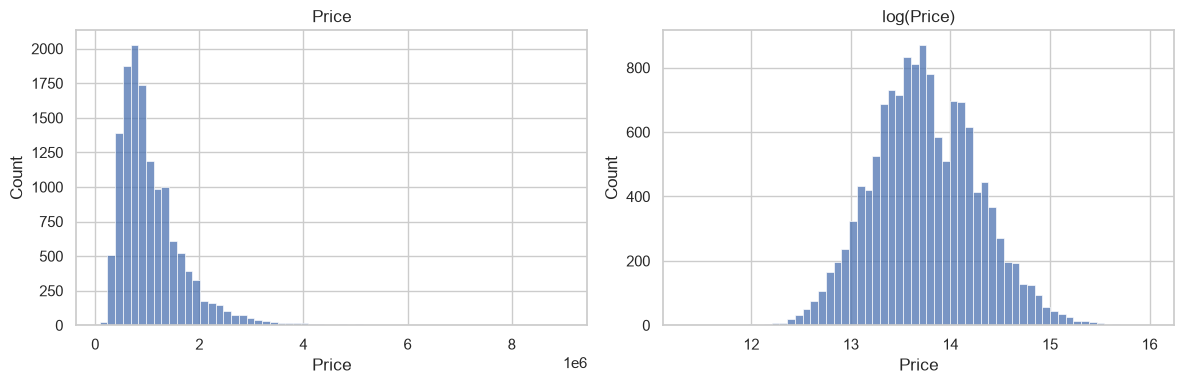

Median price: $903,000
Mean price:   $1,075,684


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price"], bins=60, ax=axes[0])
axes[0].set_title("Price")
sns.histplot(np.log(df["Price"]), bins=60, ax=axes[1])
axes[1].set_title("log(Price)")
plt.tight_layout()
plt.show()

print("Median price:", f"${df['Price'].median():,.0f}")
print("Mean price:  ", f"${df['Price'].mean():,.0f}")

**Why log?** Prices have a long tail - a few very expensive houses stretch the chart to the right (the mean ends up above the median). Taking the log squashes that tail into a nicer bell shape, which helps many models. Think of it as measuring price in "how many times bigger" instead of "how many dollars bigger".

## 4. Price by property type
`h` = house, `t` = townhouse, `u` = unit/apartment.

      count       median
Type                    
h      9449 1,080,000.00
t      1114   846,750.00
u      3017   560,000.00


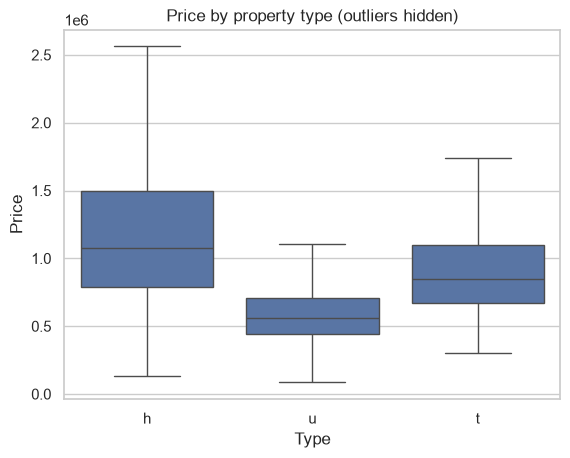

In [16]:
print(df.groupby("Type")["Price"].agg(["count", "median"]))

sns.boxplot(data=df, x="Type", y="Price", showfliers=False)
plt.title("Price by property type (outliers hidden)")
plt.show()

## 5. Price vs distance to the CBD

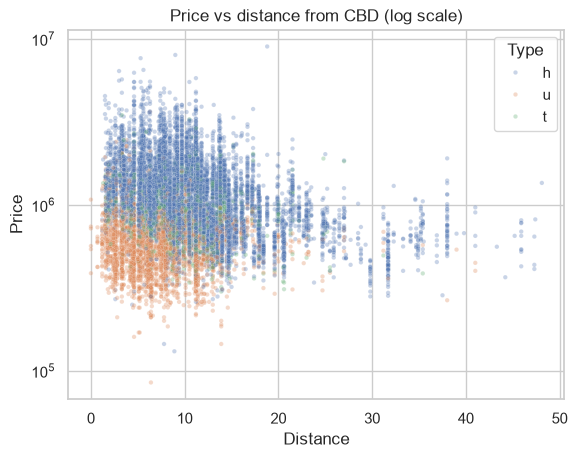

Correlation (Distance vs log Price): -0.15


In [17]:
sns.scatterplot(data=df, x="Distance", y="Price", hue="Type", alpha=0.3, s=10)
plt.yscale("log")
plt.title("Price vs distance from CBD (log scale)")
plt.show()

print("Correlation (Distance vs log Price):", round(df["Distance"].corr(np.log(df["Price"])), 2))

## 6. Price by number of rooms

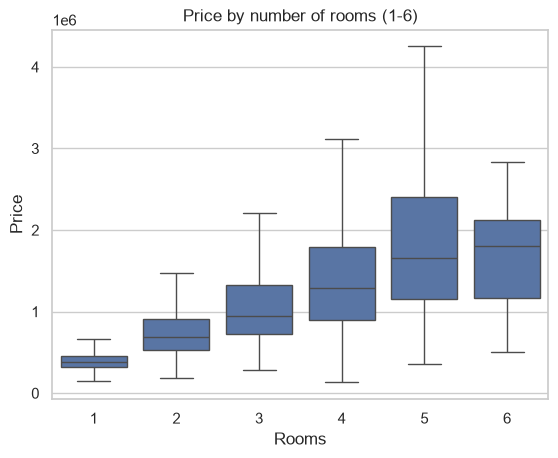

In [18]:
sns.boxplot(data=df[df["Rooms"] <= 6], x="Rooms", y="Price", showfliers=False)
plt.title("Price by number of rooms (1-6)")
plt.show()

## 7. Price by region

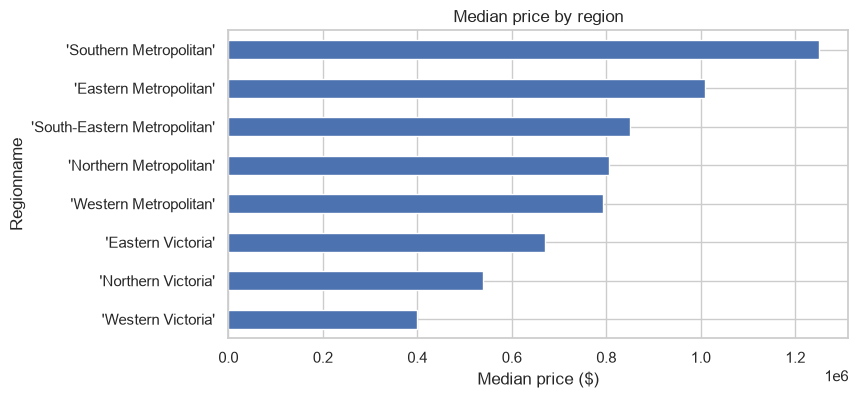

In [19]:
region = df.groupby("Regionname")["Price"].median().sort_values()
region.plot(kind="barh", figsize=(8, 4), title="Median price by region")
plt.xlabel("Median price ($)")
plt.show()

## 8. How do the numeric columns relate to price?
Correlation runs from -1 to 1. Near 0 = no straight-line relationship.

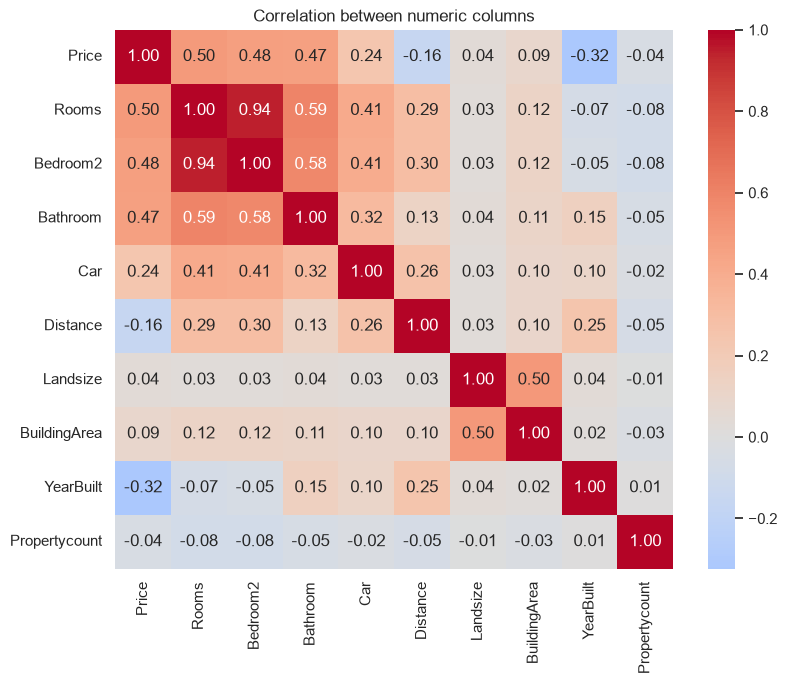

In [20]:
num_cols = ["Price", "Rooms", "Bedroom2", "Bathroom", "Car", "Distance",
            "Landsize", "BuildingArea", "YearBuilt", "Propertycount"]
corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric columns")
plt.show()

## 9. Values that look wrong
Real data has mistakes. Let's hunt for impossible values.

In [21]:
checks = {
    "Landsize = 0": (df["Landsize"] == 0).sum(),
    "BuildingArea = 0": (df["BuildingArea"] == 0).sum(),
    "YearBuilt before 1850": (df["YearBuilt"] < 1850).sum(),
    "Bedroom2 = 0 but Rooms > 0": ((df["Bedroom2"] == 0) & (df["Rooms"] > 0)).sum(),
}
pd.Series(checks).to_frame("rows")

,rows
Landsize = 0,1939
BuildingArea = 0,17
YearBuilt before 1850,2
Bedroom2 = 0 but Rooms > 0,16


In [22]:
# Rooms vs Bedroom2 - are they basically the same thing?
print("Rooms == Bedroom2 in", f"{(df['Rooms'] == df['Bedroom2']).mean():.0%}", "of rows")

Rooms == Bedroom2 in 95% of rows


In [23]:
df[df["Landsize"] == 0]["Type"].value_counts()

Type
u    1629
h     171
t     139
Name: count, dtype: int64

## Takeaways
1. **Price shape:** right-skewed - median $[X] but mean $[Y], pulled up by a few very expensive homes. I'll model log(Price) so those outliers don't dominate.
2. **Biggest drivers:** size (Rooms 0.50, Bathroom 0.47), property type (houses cost far more than units) and age (older = pricier, -0.32). Distance and land size look weak in a straight line but may matter non-linearly.
3. **Data problems to fix:** drop BuildingArea (47.5% missing) and Bedroom2 (repeats Rooms 95% of the time); fill YearBuilt and Car with medians plus a missing flag; treat YearBuilt before 1850 as missing; Landsize = 0 is mostly units, not errors.
